# Análise de exemplo: coleta completa (simulador → coletor)

Exemplo curto, de ponta a ponta, sobre as **75 gravações de 60 s** feitas em tempo real pelo simulador no coletor
(`collector/data/completa_75x60s`: 5 classes × 3 velocidades × 5 sessões). Roda em poucos minutos.

Passos: **carregar → olhar o sinal → extrair features → validar deixando uma sessão inteira de fora → ler os erros**.
A justificativa do algoritmo e os testes de robustez estão em `analise.ipynb`; aqui é só o fluxo mínimo.

> **Atenção:** os dados são **simulados** (o simulador não foi calibrado com um motor real). Os números servem para
> mostrar o método e o pipeline funcionando, e são otimistas em relação a um motor de verdade.

In [2]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import signal
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
import vibfeatures as vf

ROOT = Path.cwd()
DATA_DIR = ROOT.parent / "collector" / "data" / "completa_75x60s"
SPEED_BANDS_HZ = {"baixa": (14, 26), "media": (24, 36), "alta": (36, 54)}    # faixa esperada de 1x (setpoint do motor)
CLASSES = ["parado", "normal", "desbalanceado_leve", "desbalanceado_forte", "folga"]
COR = dict(zip(CLASSES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))    # slots 1-5 da paleta, em ordem
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "figure.dpi": 110})
print("dados:", DATA_DIR)

dados: c:\Users\rodri\Desktop\Projeto_IA\collector\data\completa_75x60s


## 1. Os dados

In [3]:
recs = vf.load_recordings(DATA_DIR)
inv = vf.inventory(recs)
print(f"{len(recs)} gravações, {inv.duracao_s.sum()/60:.0f} min de sinal, qualidade: {inv.qualidade.value_counts().to_dict()}, "
      f"pacotes perdidos: {int(inv.perdidos.sum())}")
display(pd.crosstab(inv.classe, [inv.sessao], margins=True).loc[CLASSES + ["All"]])
display(pd.crosstab(inv.classe, inv.velocidade).loc[CLASSES][["baixa", "media", "alta"]])

75 gravações, 75 min de sinal, qualidade: {'ok': 75}, pacotes perdidos: 0


sessao,4,5,6,7,8,All
classe,,,,,,
parado,3,3,3,3,3,15
normal,3,3,3,3,3,15
desbalanceado_leve,3,3,3,3,3,15
desbalanceado_forte,3,3,3,3,3,15
folga,3,3,3,3,3,15
All,15,15,15,15,15,75


velocidade,baixa,media,alta
classe,,,
parado,5,5,5
normal,5,5,5
desbalanceado_leve,5,5,5
desbalanceado_forte,5,5,5
folga,5,5,5


## 2. O sinal: espectro em ordens da rotação

Cada painel é uma gravação (sessão 4, velocidade média ≈ 1800 rpm, X+Y+Z somados). O eixo horizontal está em **ordens**
(frequência ÷ frequência de rotação): 1× é a rotação, 2× o dobro, 0,5× o sub-harmônico. Em `parado` não há rotação, então
usamos 30 Hz só como referência de escala.

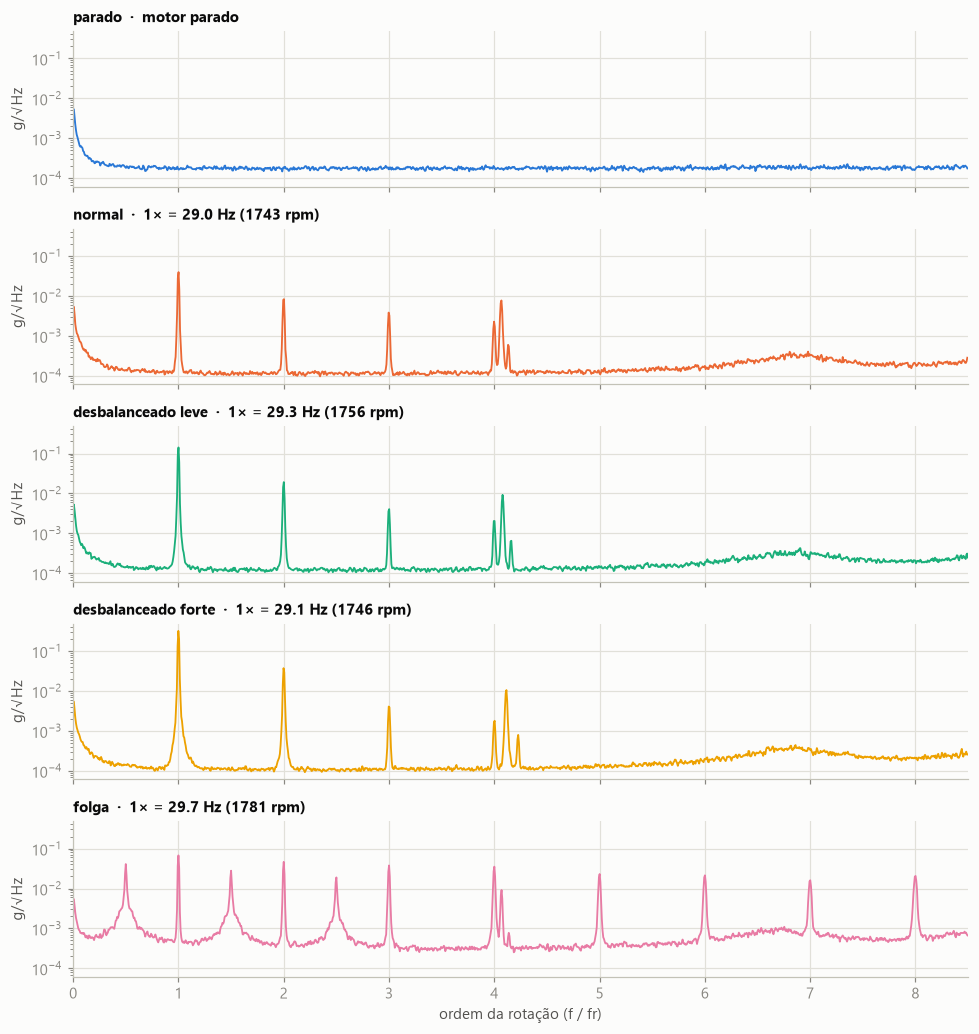

In [6]:
fig, axes = plt.subplots(len(CLASSES), 1, figsize=(9, 9.5), sharex=True, sharey=True)
for ax, c in zip(axes, CLASSES):
    r = next(r for r in recs if r.label == c and r.speed == "media" and r.session == "4")
    g = r.load()
    fr = vf.estimate_fr(g, r.fs, expected=SPEED_BANDS_HZ["media"])
    ref = fr if not np.isnan(fr) else 30.0
    f, P = signal.welch(g - g.mean(0), fs=r.fs, nperseg=8192, axis=0)
    A = np.sqrt(P.sum(axis=1)); m = f / ref <= 8.5
    ax.plot(f[m] / ref, A[m], color=COR[c], lw=1.2)
    ax.set_yscale("log"); ax.set_xlim(0, 8.5)
    for k in range(1, 9): ax.axvline(k, color=AXIS, lw=0.6, zorder=0)
    ax.set_title(c.replace("_", " ") + (f"  ·  1× = {fr:.1f} Hz ({fr*60:.0f} rpm)" if not np.isnan(fr) else "  ·  motor parado"),
                 loc="left", fontsize=10)
    ax.set_ylabel("g/√Hz")
axes[-1].set_xlabel("ordem da rotação (f / fr)")
plt.tight_layout(); plt.show()

**Leitura.** O motor parado mostra só o piso de ruído do sensor. O `normal` tem um 1× residual e harmônicos pequenos (2×, 3×), e
os picos perto de 4× são o componente elétrico (2× a frequência de alimentação). O desbalanceamento **eleva o 1×**: o forte fica
cerca de 8× acima do `normal` e o leve cerca de 3,5× (no eixo log do gráfico). A `folga` é diferente: aparecem **sub-harmônicos
(0,5×, 1,5×, 2,5×) e harmônicos até 8×**, com piso de ruído mais alto. É essa diferença de assinatura que as features em ordens
capturam.

## 3. Features

Cada gravação é cortada em **janelas de 2 s com 50 % de sobreposição**; para cada janela medimos as amplitudes nas
ordens (0,5×…8×), razões entre ordens, rms/crest/curtose, bandas e relação axial/radial. A rotação vem da faixa esperada
de cada velocidade (como o motor real teria um setpoint).

In [7]:
df = vf.build_dataset(recs, bands=SPEED_BANDS_HZ)
FEATS = vf.feature_columns(df)
X, y = df[FEATS].values, df["classe"].values
print(f"{len(df)} janelas × {len(FEATS)} features")
display(pd.crosstab(df.classe, df.velocidade).loc[CLASSES][["baixa", "media", "alta"]])

4125 janelas × 78 features


velocidade,baixa,media,alta
classe,,,
parado,275,275,275
normal,275,275,275
desbalanceado_leve,275,275,275
desbalanceado_forte,275,275,275
folga,275,275,275


## 4. Validação: uma sessão inteira de fora

Treina com 4 sessões (4 montagens do sensor) e testa na 5ª, repetindo para cada uma. É o que mede se o modelo
funciona **depois de remontar o sensor**; dividir por janelas misturaria a mesma montagem no treino e no teste.

,janelas,acurácia,F1-macro
sessão de teste,,,
4,825,0.909,0.902
5,825,1.000,1.000
6,825,0.913,0.908
7,825,0.733,0.693
8,825,0.936,0.934


F1-macro médio: 0.888 ± 0.115   |   pior sessão: 0.693


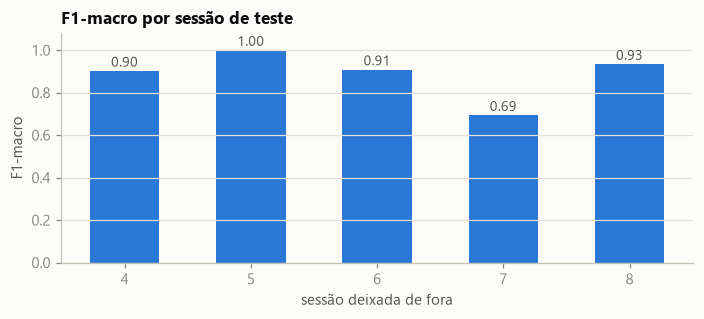

In [9]:
sess = df["sessao"].values
pred = np.empty(len(df), dtype=object); rows = []
for s in sorted(set(sess)):
    te = sess == s
    rf = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(X[~te], y[~te])
    pred[te] = rf.predict(X[te])
    rows.append({"sessão de teste": s, "janelas": int(te.sum()), "acurácia": accuracy_score(y[te], pred[te]),
                 "F1-macro": f1_score(y[te], pred[te], average="macro")})
res = pd.DataFrame(rows).set_index("sessão de teste")
display(res.round(3))
print(f"F1-macro médio: {res['F1-macro'].mean():.3f} ± {res['F1-macro'].std():.3f}   |   "
      f"pior sessão: {res['F1-macro'].min():.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3))
b = ax.bar(res.index.astype(str), res["F1-macro"], color="#2a78d6", width=0.55)
ax.set_ylim(0, 1.08); ax.set_xlabel("sessão deixada de fora"); ax.set_ylabel("F1-macro"); ax.grid(axis="x", visible=False)
for rect, v in zip(b, res["F1-macro"]): ax.text(rect.get_x() + rect.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", color=INK2, fontsize=9)
ax.set_title("F1-macro por sessão de teste", loc="left"); plt.tight_layout(); plt.show()

## 5. Onde o modelo erra

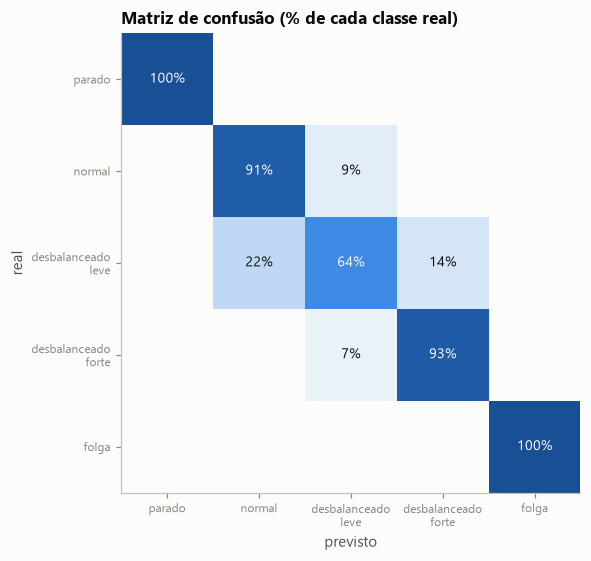

velocidade,baixa,media,alta
recall por velocidade,,,
parado,1.000,1.000,1.0
normal,0.804,0.935,1.0
desbalanceado_leve,0.753,0.582,0.6
desbalanceado_forte,0.996,0.804,1.0
folga,1.000,1.000,1.0


In [10]:
cm = confusion_matrix(y, pred, labels=CLASSES); cmn = cm / cm.sum(1, keepdims=True)
cmap = LinearSegmentedColormap.from_list("azul", ["#fcfcfb", "#9ec5f4", "#3987e5", "#184f95"])
fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.imshow(cmn, cmap=cmap, vmin=0, vmax=1); ax.grid(False)
names = [c.replace("_", "\n") for c in CLASSES]
ax.set_xticks(range(5), names, fontsize=8); ax.set_yticks(range(5), names, fontsize=8)
ax.set_xlabel("previsto"); ax.set_ylabel("real")
for i in range(5):
    for j in range(5):
        if cm[i, j]: ax.text(j, i, f"{cmn[i, j]*100:.0f}%", ha="center", va="center", fontsize=9,
                             color="#ffffff" if cmn[i, j] > 0.55 else INK)
ax.set_title("Matriz de confusão (% de cada classe real)", loc="left"); plt.tight_layout(); plt.show()

d = pd.DataFrame({"classe": y, "velocidade": df.velocidade.values, "acerto": y == pred})
display((d.pivot_table(index="classe", columns="velocidade", values="acerto", aggfunc="mean").loc[CLASSES][["baixa", "media", "alta"]]).round(3)
        .rename_axis("recall por velocidade"))

### Conclusões do exemplo

* **Resultado:** com validação por sessão, o Random Forest chega a **F1-macro 0,89 ± 0,11** (pior sessão 0,69; melhor 1,00). É a
  mesma faixa do dataset gerado offline em `analise.ipynb` (0,92 ± 0,11); com 5 sessões e esse desvio, a diferença não é
  significativa.
* **O que funciona:** `parado` e `folga` são reconhecidos em 100 % das janelas e `desbalanceado_forte` em 93 %. O espectro em
  ordens separa bem essas classes (folga tem muitos harmônicos e sub-harmônicos; peso forte tem 1× muito alto).
* **O que não funciona tão bem:** o `desbalanceado_leve` é a classe difícil: só 64 % de recall, confundido com `normal` (22 %) e
  com `forte` (14 %). Um peso pequeno só eleva um pouco o 1× que o motor saudável já tem, então a fronteira depende do 1× residual
  daquela montagem do sensor. O erro está concentrado em poucas sessões (a sessão 7 explica a maior parte da queda).
* **Limitação:** os dados são simulados e as sessões 4 a 8 são só 5 remontagens. Os mesmos passos valem para dados reais de um
  motor: troque `DATA_DIR`, ajuste `SPEED_BANDS_HZ` e os nomes das classes.